In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from workload_data_loader import load_workload_instance

In [2]:
n, m, utilities, demands, capacities = load_workload_instance("multi_resource_n28_m2.txt")


df = pd.DataFrame({"utility": utilities, **{f"resource_{i+1}": demands[i] for i in range(m)}})
print(demands)

[[ 45.   0.  85. 150.  65.  95.  30.   0. 170.   0.  40.  25.  20.   0.
    0.  25.   0.   0.  25.   0. 165.   0.  85.   0.   0.   0.   0. 100.]
 [ 30.  20. 125.   5.  80.  25.  35.  73.  12.  15.  15.  40.   5.  10.
   10.  12.  10.   9.   0.  20.  60.  40.  50.  36.  49.  40.  19. 150.]]


In [3]:
def evaluate(solution):
    # m is the number of resource bounds, in this case it will be 2
    # sum(iterable, start), if no np.zeros, the weight will be out of bounds as a set
    weight = sum((demands[:, i] for i in solution), np.zeros(m))
    value = sum(utilities[i] for i in solution)
    return weight, value

def fits(weight):
    return np.all(weight <= capacities)  # checks if all the resources under the capacity

def penalized_score(solution, penalty_weight=2000):
    weight, value = evaluate(solution)
    excess = np.maximum(0, weight - capacities)  # overflow per resource
    return value - penalty_weight * np.sum(excess)


def hill_climbing(seed=None, penalty_weight=2000):
    if seed is None:
        solution = set()  # Set up an empty starting solution
    else:
        np.random.seed(seed)
        # Random starting subset (may be infeasible; penalty guides it to feasibility)
        solution = {i for i in range(n) if np.random.rand() < 0.5}

    history = []
    while True:
        current_score = penalized_score(solution, penalty_weight)
        history.append(current_score)
        best_neighbor = solution #convert to best neighbor and best value to compare
        best_score = current_score

        # Neighbors: add, remove, or swap one model
        for i in range(n):  #n: the number of models, in this case: 28
            if i not in solution:
                candidate = solution | {i}  # Add the neighbor
                score = penalized_score(candidate, penalty_weight)

                if score > best_score:
                    best_neighbor = candidate
                    best_score = score

            else:
                candidate = solution - {i}  # Remove
                score = penalized_score(candidate, penalty_weight)

                if score > best_score:
                    best_neighbor = candidate
                    best_score = score


                for j in range(n):
                    if j not in solution:
                        candidate = (solution - {i}) | {j}  # Swap the resources values
                        score = penalized_score(candidate, penalty_weight)

                        if score > best_score:
                            best_neighbor = candidate
                            best_score = score

        # Stop if no improvement
        if best_neighbor == solution:
            break

        solution = best_neighbor

    return solution, history

# Show result
solution, _ = hill_climbing()
weight, value = evaluate(solution)

print("Selected models:")
for i in sorted(solution):
    print("Model", i, "- Demands:", demands[:, i], "Utility:", utilities[i])

print("Total resource used:", weight, "/ Capacity:", capacities)
print("Total utility:", value)


Selected models:
Model 2 - Demands: [ 85. 125.] Utility: 22507.0
Model 4 - Demands: [65. 80.] Utility: 14148.0
Model 6 - Demands: [30. 35.] Utility: 4650.0
Model 7 - Demands: [ 0. 73.] Utility: 30800.0
Model 9 - Demands: [ 0. 15.] Utility: 4975.0
Model 10 - Demands: [40. 15.] Utility: 1160.0
Model 13 - Demands: [ 0. 10.] Utility: 11880.0
Model 18 - Demands: [25.  0.] Utility: 110.0
Model 20 - Demands: [165.  60.] Utility: 24355.0
Model 22 - Demands: [85. 50.] Utility: 11748.0
Model 23 - Demands: [ 0. 36.] Utility: 4550.0
Total resource used: [495. 499.] / Capacity: [500. 500.]
Total utility: 130883.0


In [6]:
results = []
times = []
histories = []
best_sol = None
best_val = -1

for run in range(20):
    t0 = time.perf_counter()
    sol, hist = hill_climbing(seed=run)
    times.append(time.perf_counter() - t0)

    weight, value = evaluate(sol)
    assert fits(weight)
    results.append(value)
    histories.append(hist)
    if value > best_val:
        best_val = value
        best_sol = sol

print("Best:", max(results))
print("Mean:", np.mean(results))
print("Median:", np.median(results))
print("Std:", np.std(results))
print(f"Mean runtime: {np.mean(times):.4f}s | Total runtime: {np.sum(times):.4f}s")
print("Best models:", sorted(best_sol))
print("Best resource used:", evaluate(best_sol)[0], "/", capacities)


Best: 129173.0
Mean: 117007.7
Median: 119121.0
Std: 9866.870928009548
Mean runtime: 0.0830s | Total runtime: 1.6604s
Best models: [2, 4, 6, 7, 9, 10, 12, 13, 16, 20, 22, 26]
Best resource used: [490. 497.] / [500. 500.]


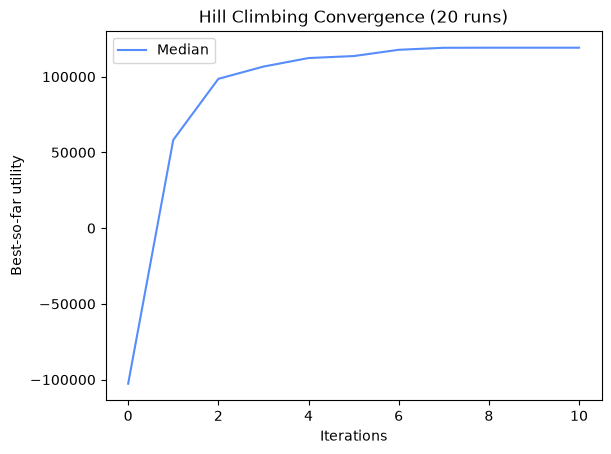

In [11]:
# Pad shorter runs with their final value so history is a 2D array (runs, iterations)
max_len = max(len(h) for h in histories) #max len of all runs (20)
history = np.array([h + [h[-1]] * (max_len - len(h)) for h in histories]) #fill an array with less iteration than the array have highest number of iterations to avoid errors of shapes when representing in graphs

best_so_far = np.maximum.accumulate(history, axis=1)
med = np.median(best_so_far, axis=0)
plt.plot(med, label="Median")
plt.xlabel("Iterations")
plt.ylabel("Best-so-far utility")
plt.title("Hill Climbing Convergence (20 runs)")
plt.legend()
plt.show()


#### Part 1: Baseline Discrete Local Search
For this part, I'm using a baseline local search (hill-climbing) to find best models to have best result. \
The model is a basic model with add and remove operators with a static constraint handling algorithm, and the reason why I choose local search because the dataset is small and stated that it is used for baseline local search, testing and validation, there is 1 problem of this model is that the randomize might not work, the model can be not improved everytime it runs as it shows no learning from times to times, for example, first iteration can give a good value/result, but it will give less value result in the next one, which consumes a lot of computation resources. At the same time I have applied static penalty constrant to approach constraint handling, this constrant is easy to apply and preserve the result, however, the critical disadvange of this approach is that it needs its panalty weight choosen carefully.\

As the result of 20 runs (for-loop), the mean time that this model finds a solution is 0.0830s, total time to complete the for-loop is around 1.6s. The best models are 2, 4, 6, 7, 9, 10, 12, 13, 16, 20, 22 and 26 to generate the highest value, and also it nearly uses all resources with 490/500 and 497/500.

Regarding the convergence graph, in all 20 runs, the maximum iterations to find the best solution is 11 iterations. In the y-axis, it shows the best-so-far metrics, however, in iteration 1, it will have minus have to go because some runs can exceed the capacity, which penalties hit it. Overall the graph show that best-so-far value gradually increased.

In [15]:
print(med)

[-102688.    58230.5   98560.5  106650.   112294.5  113590.5  117738.
  119066.   119121.   119121.   119121. ]
